In [1]:

## STEP 1: Load all files and check them

# Input: 4 CSV files (ERP cluster RS, component RS, spectral RS, clinical/demographic)
# Output: 4 cleaned DataFrames — ID-ASD/ID-control excluded, missing codes (777/999) set to NaN, N2 columns dropped, Age_Group standardised

import pandas as pd
import numpy as np

# Load ERP cluster data
erp_data = pd.read_csv('C:/Users/cigde/Dropbox/Habituation_paper/October_Emily/input_arrays/pls_regression/cluster_RS_all_ages.csv', dtype={'UniqueID': str})

# Load component data
component_data = pd.read_csv('C:/Users/cigde/Dropbox/Habituation_paper/October_Emily/input_arrays/pls_regression/component_RS_all_ages.csv', dtype={'UniqueID': str})

# Load clinical data
clinical_data = pd.read_csv('C:/Users/cigde/Dropbox/Habituation_paper/October_Emily/input_arrays/pls_regression/demog_clin_data.csv', dtype={'UniqueID': str})

# Convert IDs to string
erp_data['UniqueID'] = erp_data['UniqueID'].astype(str)
clinical_data['UniqueID'] = clinical_data['UniqueID'].astype(str)

# Filter out ID-ASD and ID-control
clinical_data_filtered = clinical_data[
    ~clinical_data['group_original'].isin(['ID-ASD', 'ID-control'])
].copy()

# Replace missing codes
clinical_data_filtered = clinical_data_filtered.replace([777, 999], np.nan)

## Step 1b: Sort clinical data
age_order = {'Child': 1, 'Adolescent': 2, 'Adult': 3}
group_order = {'TD': 1, 'ASD': 2}
clinical_data_filtered['age_sort'] = clinical_data_filtered['schedule_adj'].map(age_order)
clinical_data_filtered['group_sort'] = clinical_data_filtered['group_original'].map(group_order)
clinical_data_filtered_sorted = clinical_data_filtered.sort_values(
    by=['age_sort', 'group_sort']
).reset_index(drop=True)
clinical_data_filtered_sorted = clinical_data_filtered_sorted.drop(['age_sort', 'group_sort'], axis=1)

# Drop N2 columns from component data (unreliable from adolescence onwards)
component_data = component_data.drop(columns=['N2_amp_diff', 'N2_lat_diff'])

# Standardise Age_Group capitalisation to title case across all files
erp_data['Age_Group'] = erp_data['Age_Group'].str.title()
component_data['age_group'] = component_data['age_group'].str.title()

## Print to check all four files
# print("Cluster RS Data:")
# print(erp_data.head(3))
# print(f"Shape: {erp_data.shape} | Columns: {erp_data.columns.tolist()}")

# print("\n" + "="*70)
# print("Component RS Data:")
# print(component_data.head(3))
# print(f"Shape: {component_data.shape} | Columns: {component_data.columns.tolist()}")

# print("\n" + "="*70)
# print("Clinical Data:")
# print(clinical_data_filtered_sorted[['UniqueID', 'group_original', 'schedule_adj',
#                                       'age_years', 'fsiq', 'SRS_tscore']].head(3))

# print(f"Shape: {clinical_data_filtered_sorted.shape}")
# print(f"Group counts: {clinical_data_filtered_sorted['group_original'].value_counts()}")

In [2]:
## STEP 2: Merge all three files (component, cluster and demographic)  on UniqueID

# Input: 4 DataFrames from STEP 1
# Output: Single merged DataFrame with all EEG + clinical variables, duplicate columns removed

# Step 2a: Standardise age_group capitalisation to lowercase for merging
erp_data['Age_Group'] = erp_data['Age_Group'].str.lower()
component_data['age_group'] = component_data['age_group'].str.lower()

# Step 2b: Merge erp and component files on UniqueID
erp_component = pd.merge(erp_data, component_data, on='UniqueID', how='inner')

# Step 2c: Merge with clinical on UniqueID
merged_data = pd.merge(erp_component, clinical_data_filtered_sorted, on='UniqueID', how='inner')

# Step 2d: Clean up duplicate columns
cols_to_drop = ['Group', 'Age_Group', 'group_x', 'group_y', 'schedule_enrol', 'age']
merged_data = merged_data.drop(columns=cols_to_drop)


# Verify
print("MERGE SUMMARY:")
print("="*70)
print(f"Cluster RS subjects:    {len(erp_data)}")
print(f"Component RS subjects:  {len(component_data)}")
print(f"Clinical subjects:      {len(clinical_data_filtered_sorted)}")
print(f"Final merged subjects:  {len(merged_data)}")
print(f"\nBy group: {merged_data['group_original'].value_counts().to_dict()}")
print(f"Total columns: {len(merged_data.columns)}")
print(f"\nColumns: {merged_data.columns.tolist()}")


MERGE SUMMARY:
Cluster RS subjects:    375
Component RS subjects:  375
Clinical subjects:      653
Final merged subjects:  375

By group: {'ASD': 202, 'TD': 173}
Total columns: 30

Columns: ['SubjectID_x', 'UniqueID', 'frontocentral_W50_100', 'frontocentral_W100_150', 'frontocentral_W150_200', 'frontocentral_W200_250', 'frontocentral_W250_300', 'SubjectID_y', 'age_group', 'P1_amp_diff', 'N1_amp_diff', 'P2_amp_diff', 'P1_lat_diff', 'N1_lat_diff', 'P2_lat_diff', 'group_original', 'schedule_adj', 'sex', 'viq', 'piq', 'fsiq', 'age_years', 'CSS_total', 'SRS_tscore', 'SSP_tactile', 'SSP_audfilt', 'SSP_visualaudisens', 'SSP_total', 'SSP_hype', 'SSP_hypo']


In [3]:

# STEP 3a: Define EEG feature matrix and clinical variables
# Input: Merged DataFrame from STEP 2
# Output: EEG feature matrix (8 amplitude features, rows with missing EEG dropped), clinical variable list defined for later characterisation

# EEG features for clustering 
eeg_features = [
    # FC cluster RS (5 time windows)
    'frontocentral_W50_100', 'frontocentral_W100_150', 'frontocentral_W150_200',
    'frontocentral_W200_250', 'frontocentral_W250_300',
    # Component amplitude / latency diffs (N2 removed)
    'P1_amp_diff', 'N1_amp_diff', 'P2_amp_diff', 
    'P1_lat_diff', 'N1_lat_diff', 'P2_lat_diff',
]

# Clinical variables for cluster characterisation 
clinical_features = ['age_years', 'viq', 'piq', 'fsiq', 'SRS_tscore', 'SSP_total', 'CSS_total']

# Extract EEG matrix and drop rows with any missing EEG values
X_eeg = merged_data[eeg_features].copy()
X_eeg_complete = X_eeg.dropna(axis=0, how='any')
dropped = len(X_eeg) - len(X_eeg_complete)

print(f"Total subjects before removal due to missing EEG features: {len(X_eeg)}")
print(f"Subjects dropped (missing EEG data): {dropped}")
print(f"Subjects retained for clustering: {len(X_eeg_complete)}")
print(f"Number of EEG features: {len(eeg_features)}")
print(f"\nMissingness per feature:\n{X_eeg.isna().sum()[X_eeg.isna().sum() > 0]}")

Total subjects before removal due to missing EEG features: 375
Subjects dropped (missing EEG data): 0
Subjects retained for clustering: 375
Number of EEG features: 11

Missingness per feature:
Series([], dtype: int64)


In [4]:
# STEP 3b: IQR-based outlier removal across all EEG features
# Outliers are removed one feature at a time. After each feature's outliers are removed,
# the IQR boundaries for the next feature are recalculated on the reduced dataset.
# This makes the procedure order-dependent: the sequence of features affects which
# subjects are removed. Boundaries are Q1 - 2.5*IQR and Q3 + 2.5*IQR per feature.

# Input:  Merged DataFrame filtered to subjects with complete EEG data
# Output: Cleaned DataFrame and updated EEG feature matrix with outliers removed

def remove_outliers_col(df, col):
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    return df[(df[col] >= Q1 - 2.5*IQR) & (df[col] <= Q3 + 2.5*IQR)]

# Start from full merged data, apply IQR removal iteratively across all EEG features
df_clean = merged_data.loc[X_eeg_complete.index].copy()

# Confirm index alignment between df_clean and merged_data
assert all(df_clean.index.isin(merged_data.index)), "Index mismatch — df_clean contains indices not in merged_data"
assert all(df_clean['UniqueID'] == merged_data.loc[df_clean.index, 'UniqueID']), "UniqueID mismatch after index alignment"
print(f"Index alignment check passed — {len(df_clean)} subjects correctly aligned")

n_before = len(df_clean)

for col in eeg_features:
    df_clean = remove_outliers_col(df_clean, col)

n_after = len(df_clean)
print(f"Subjects before outlier removal: {n_before}")
print(f"Subjects after outlier removal:  {n_after}")
print(f"Subjects removed: {n_before - n_after}")

# Redefine X_eeg_complete from cleaned data
X_eeg_complete = df_clean[eeg_features].copy()
print(f"\nFeature matrix shape after outlier removal: {X_eeg_complete.shape}")

Index alignment check passed — 375 subjects correctly aligned
Subjects before outlier removal: 375
Subjects after outlier removal:  333
Subjects removed: 42

Feature matrix shape after outlier removal: (333, 11)


Age residualisation complete.
Feature matrix shape: (333, 11)
Running k=2...


C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


  k=2 done. Inertia=2698.7
Running k=3...


C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


  k=3 done. Inertia=2370.5
Running k=4...


C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


... (5 outputs left out)

C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


  k=7 done. Inertia=1882.1
Running k=8...


C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


  k=8 done. Inertia=1808.6


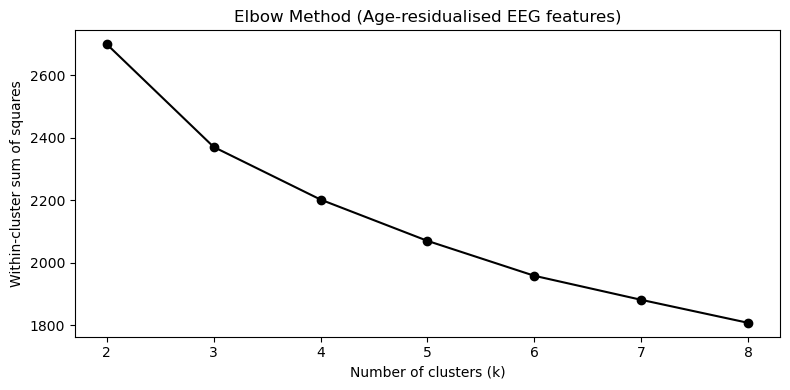

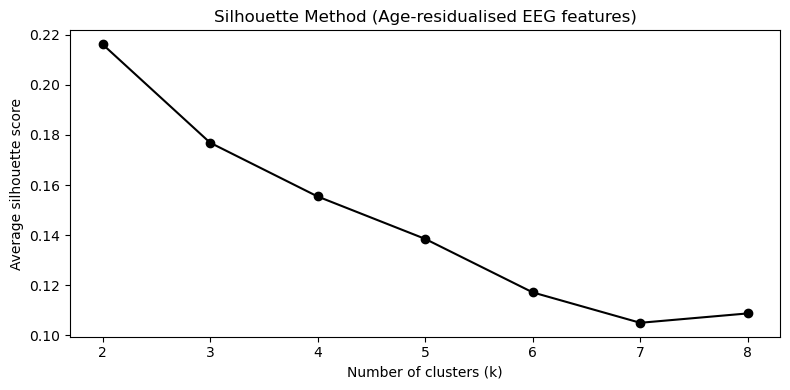


k | Inertia | Silhouette
2  | 2698.7  | 0.2161
3  | 2370.5  | 0.1769
4  | 2202.4  | 0.1554
5  | 2070.5  | 0.1385
6  | 1958.9  | 0.1172
7  | 1882.1  | 0.1051
8  | 1808.6  | 0.1088


In [5]:
# STEP 4: Age residualisation, standardisation, k selection

# Input: Cleaned EEG feature matrix + age variable
# Output: Age-residualised, z-scored feature matrix; elbow and silhouette plots for k=2–8

# Elbow method: shows how tightly points sit within their clusters as k increases.
#   The best k is where adding more clusters stops making the fit much better.
# Silhouette method: shows how well-separated the clusters are. The best k is the
#   one with the highest score.


import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression

# Residualise age out of all EEG features 
age = merged_data.loc[X_eeg_complete.index, 'age_years'].values.reshape(-1, 1)
X_eeg_resid = X_eeg_complete.copy()

for col in eeg_features:
    lr = LinearRegression()
    lr.fit(age, X_eeg_complete[col].values)
    X_eeg_resid[col] = X_eeg_complete[col].values - lr.predict(age)

print("Age residualisation complete.")
print(f"Feature matrix shape: {X_eeg_resid.shape}")

# --- Standardise residualised features ---
scaler_b = StandardScaler()
X_scaled_b = scaler_b.fit_transform(X_eeg_resid)

#  Elbow and silhouette for k = 2 to 8 
k_range = range(2, 9)
inertia_b = []
silhouette_b = []

for k in k_range:
    print(f"Running k={k}...", flush=True)
    kmeans_b = KMeans(n_clusters=k, random_state=0, n_init=100)
    kmeans_b.fit(X_scaled_b)
    inertia_b.append(kmeans_b.inertia_)
    silhouette_b.append(silhouette_score(X_scaled_b, kmeans_b.labels_))
    print(f"  k={k} done. Inertia={kmeans_b.inertia_:.1f}")

# --- Elbow plot ---
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), inertia_b, 'o-', color='black')
plt.title('Elbow Method (Age-residualised EEG features)')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Within-cluster sum of squares')
plt.grid(False)
plt.tight_layout()
plt.show()

# --- Silhouette plot ---
plt.figure(figsize=(8, 4))
plt.plot(list(k_range), silhouette_b, 'o-', color='black')
plt.title('Silhouette Method (Age-residualised EEG features)')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Average silhouette score')
plt.grid(False)
plt.tight_layout()
plt.show()

# --- Print scores ---
print("\nk | Inertia | Silhouette")
for k, iner, sil in zip(k_range, inertia_b, silhouette_b):
    print(f"{k}  | {iner:.1f}  | {sil:.4f}")


## To decide how many clusters best describe the data, we look at two measures together. The silhouette score, which tells us how cleanly 
    # separated the clusters are, was highest at k=2 and then dropped as we added more clusters. This means two clusters gave the tidiest split.
    # The elbow plot backs this up: most of the improvement in fit happens by k=2, and adding more clusters after that improves the fit (i.e.
    # how well the clusters capture the structure in the data) very little. Both point the same way, so I went with two clusters

In [6]:

## STEP 5: Fit k-means (k=2)

# Input: Z-scored age-residualised feature matrix
# Output: Cluster labels assigned, df_clustered_b with cluster column added

from sklearn.decomposition import PCA
from scipy import stats

# Fit k-means with k=2 
k = 2
kmeans_b = KMeans(n_clusters=k, random_state=0, n_init=100)
kmeans_b.fit(X_scaled_b)
groupidx_b = kmeans_b.labels_
cents_b = kmeans_b.cluster_centers_

#  Cluster sizes
unique, counts = np.unique(groupidx_b, return_counts=True)
print("Cluster sizes:")
for u, c in zip(unique, counts):
    print(f"  Cluster {u+1}: {c} participants")

#  Check: index alignment 
df_clustered_b = merged_data.loc[X_eeg_complete.index].copy()
df_clustered_b['cluster'] = groupidx_b
assert all(df_clustered_b.index.isin(merged_data.index)), "Index mismatch — df_clustered_b contains indices not in merged_data"
assert all(df_clustered_b['UniqueID'] == merged_data.loc[df_clustered_b.index, 'UniqueID']), "UniqueID mismatch in df_clustered_b"
assert len(df_clustered_b) == len(groupidx_b), f"Length mismatch: df_clustered_b has {len(df_clustered_b)} rows but groupidx_b has {len(groupidx_b)} labels"
print(f"Index alignment check passed — {len(df_clustered_b)} subjects, {len(groupidx_b)} cluster labels")
    

C:\Users\cigde\anaconda3\envs\habituation_regression\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Cluster sizes:
  Cluster 1: 148 participants
  Cluster 2: 185 participants
Index alignment check passed — 333 subjects, 333 cluster labels


In [8]:
# Save cluster labels for cross-comparison between feature sets.
# Cluster numbering is arbitrary within each run, so these files are used
# to check whether the temporal and spectral analyses assign the same
# participants to the same groups (cross-tabulation and ARI, run separately).

import os
fig_path = r'C:/Users/cigde/Dropbox/Habituation_paper/October_Emily/final_figures'

df_clustered_b.reset_index()[['UniqueID', 'cluster']].to_csv(
    os.path.join(fig_path, 'labels_temporal_kmeans.csv'), index=False)

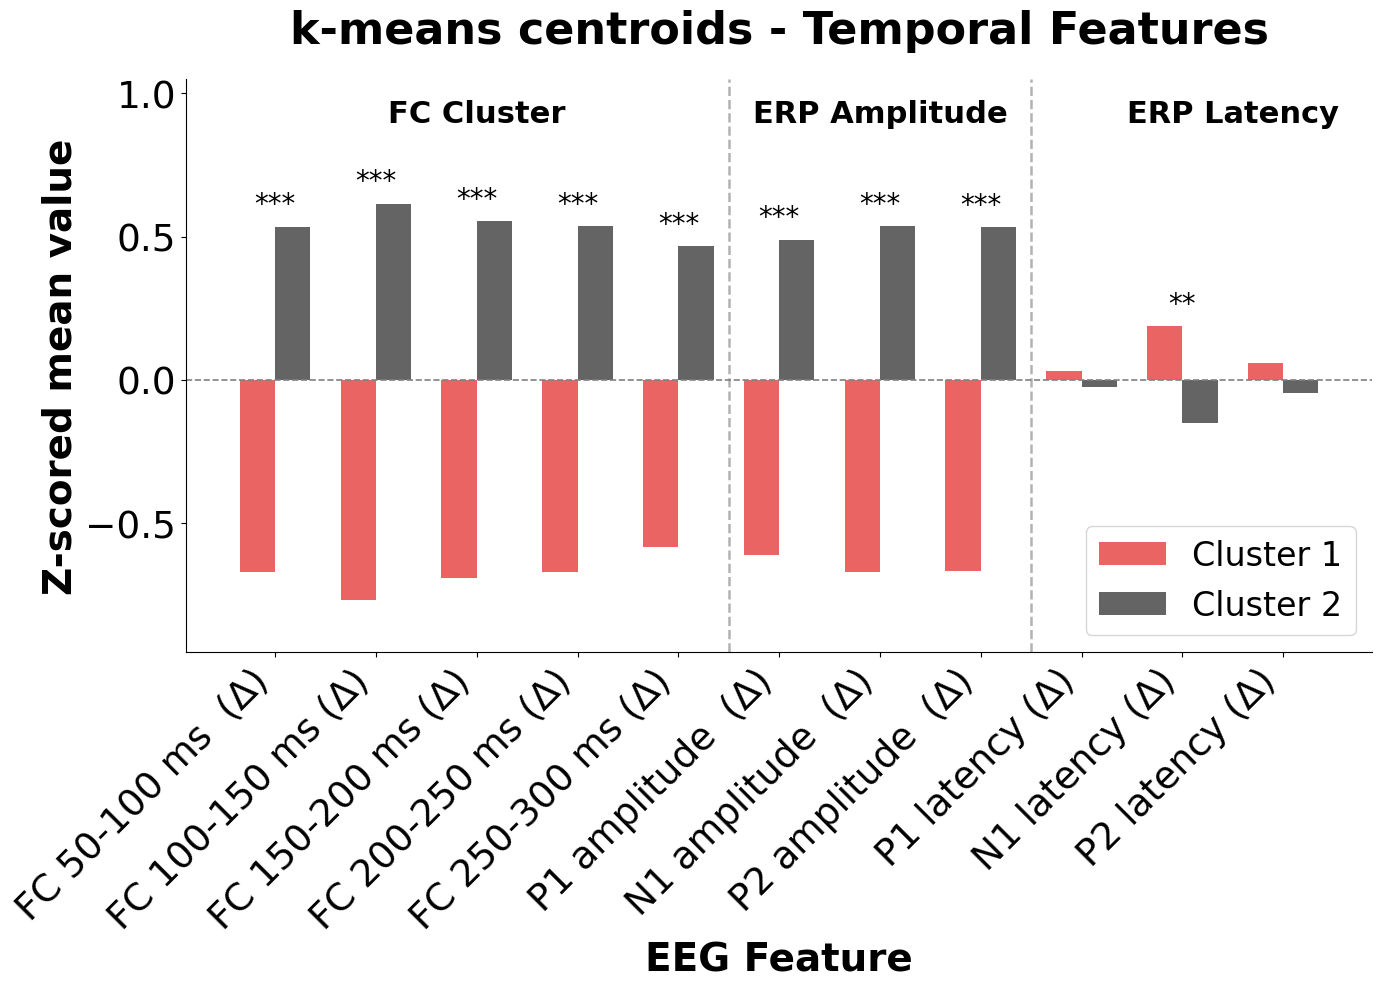

In [22]:
# Step 6:  Centroid profile plot (bar plot) 

# Input: Cluster centroids, cluster labels, EEG features
# Output: Bar plot showing z-scored centroid values per cluster with significance markers

from scipy import stats
import pandas as pd
import os
from statsmodels.stats.multitest import multipletests
import json

with open(r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\label_map.json', encoding='utf-8') as f:
    label_map = json.load(f)

new_labels = [label_map.get(f, f) for f in eeg_features]

# --- Stats for each EEG feature between clusters (BH-corrected) ---
pvals = []
for feat in eeg_features:
    c1_vals = X_eeg_resid.loc[df_clustered_b['cluster'] == 0, feat].dropna()
    c2_vals = X_eeg_resid.loc[df_clustered_b['cluster'] == 1, feat].dropna()
    _, p_norm1 = stats.shapiro(c1_vals)
    _, p_norm2 = stats.shapiro(c2_vals)
    if p_norm1 > 0.05 and p_norm2 > 0.05:
        _, p = stats.ttest_ind(c1_vals, c2_vals)
    else:
        _, p = stats.mannwhitneyu(c1_vals, c2_vals, alternative='two-sided')
    pvals.append(p)

_, p_fdr, _, _ = multipletests(pvals, method='fdr_bh')

sig_markers = ['***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
               for p in p_fdr]

# Bar plot 

# font sizes
fs_tick  = 27
fs_label = 28
fs_title = 32

colors = ['#e32222', '#222222']
x = np.arange(len(eeg_features))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 10))
bars1 = ax.bar(x - width/2, cents_b[0, :], width, color=colors[0], alpha=0.7, label='Cluster 1')
bars2 = ax.bar(x + width/2, cents_b[1, :], width, color=colors[1], alpha=0.7, label='Cluster 2')


ax.set_xticks(x)
ax.set_xticklabels(new_labels, rotation=45, ha='right', fontsize=fs_tick)
ax.tick_params(axis='y', labelsize=fs_tick)
ax.set_xlabel('EEG Feature', fontsize=fs_label, fontweight='bold')
ax.set_ylabel('Z-scored mean value', fontsize=fs_label, fontweight='bold')
ax.set_title('k-means centroids - Temporal Features', fontsize=fs_title, fontweight='bold', pad=26)
ax.axhline(0, color='grey', linewidth=1.2, linestyle='--')

# Vertical separators 
ax.axvline(4.5, color='grey', linewidth=1.8, linestyle='--', alpha=0.6)
ax.axvline(7.5, color='grey', linewidth=1.8, linestyle='--', alpha=0.6)

# Significance markers 
for i, marker in enumerate(sig_markers):
    if marker:
        y_pos = max(cents_b[0, i], cents_b[1, i]) + 0.05
        ax.text(i, y_pos, marker, ha='center', fontsize=20, color='black')

        
# Group labels 
ax.set_ylim(-0.95, 1.05)
ax.text(2, 0.90, 'FC Cluster', ha='center', fontsize=22, fontweight='bold', color='black')
ax.text(6, 0.90, 'ERP Amplitude', ha='center', fontsize=22, fontweight='bold', color='black')
ax.text(9.5, 0.90, 'ERP Latency', ha='center', fontsize=22, fontweight='bold', color='black')

# ax.legend(fontsize=14, loc='upper right', bbox_to_anchor=(1.15, 1)) # if we want legend outside the plot add bbox argument
ax.legend(fontsize=24, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()

# save bar plots as figure_6
fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\figure_6'
os.makedirs(fig_path, exist_ok=True)

#plt.savefig(os.path.join(fig_path, 'figure6D.png'), format='png', dpi=300, bbox_inches='tight')
#plt.savefig(os.path.join(fig_path, 'figure6D.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure6D.tiff'), format='tiff', dpi=300, bbox_inches='tight')

plt.show()


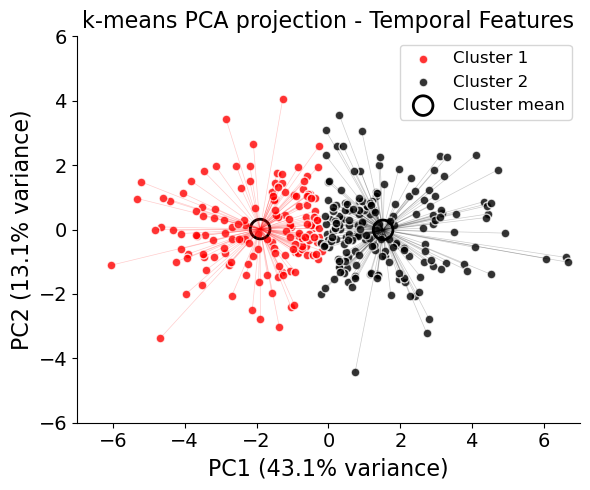

In [10]:
# STEP 7: PCA 2D visualisation

# Input: Z-scored feature matrix, cluster labels
# Output: Scatter plot of subjects in PC1/PC2 space with cluster centroids and connecting lines

# font sizes
fs_tick  = 14
fs_label = 16
fs_title = 16
fs_leg   = 12


colors = ['red', 'black']
pca_b = PCA(n_components=2)
data_2d_b = pca_b.fit_transform(X_scaled_b)
cents_2d_b = np.array([data_2d_b[groupidx_b == i].mean(axis=0) for i in range(k)])

fig, ax = plt.subplots(figsize=(6, 5))
for i, c in enumerate(colors):
    ax.scatter(data_2d_b[groupidx_b == i, 0], data_2d_b[groupidx_b == i, 1],
               color=c, edgecolor='w', s=40, alpha=0.8, label=f'Cluster {i+1}')
    for j in range(len(data_2d_b)):
        if groupidx_b[j] == i:
            ax.plot([data_2d_b[j, 0], cents_2d_b[i, 0]],
                    [data_2d_b[j, 1], cents_2d_b[i, 1]],
                    color=c, alpha=0.2, linewidth=0.5)
ax.scatter(cents_2d_b[:, 0], cents_2d_b[:, 1], facecolor='none', edgecolor='k',
           s=200, linewidth=2, marker='o', label='Cluster mean')

ax.set_title('k means PCA projection - Temporal Features', fontsize=fs_title)
ax.set_xlabel(f'PC1 ({pca_b.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=fs_label)
ax.set_ylabel(f'PC2 ({pca_b.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=fs_label)
ax.tick_params(axis='both', labelsize=fs_tick)
ax.legend(fontsize=fs_leg, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlim(-7, 7)
ax.set_ylim(-6, 6)
plt.tight_layout()

fig_path = r'C:\Users\cigde\Dropbox\Habituation_paper\October_Emily\final_figures\figure_6'
os.makedirs(fig_path, exist_ok=True)

# plt.savefig(os.path.join(fig_path, 'figure6A.png'), format='png', dpi=300, bbox_inches='tight')
# plt.savefig(os.path.join(fig_path, 'figure6A.pdf'), format='pdf', bbox_inches='tight')
plt.savefig(os.path.join(fig_path, 'figure6A.tiff'), format='tiff', dpi=300, bbox_inches='tight')

plt.show()

In [11]:
# Step 7b: Print PCA output

print(f"\nPCA variance explained: PC1={pca_b.explained_variance_ratio_[0]*100:.1f}%, "
      f"PC2={pca_b.explained_variance_ratio_[1]*100:.1f}%")
print("\nGroup distribution per cluster:")
print(pd.crosstab(df_clustered_b['cluster'], df_clustered_b['group_original']))
print("\nAge group distribution per cluster:")
print(pd.crosstab(df_clustered_b['cluster'], df_clustered_b['age_group']))


PCA variance explained: PC1=43.1%, PC2=13.1%

Group distribution per cluster:
group_original  ASD  TD
cluster                
0                78  70
1               102  83

Age group distribution per cluster:
age_group  adol  adult  child
cluster                      
0            67     42     39
1            62     64     59


In [12]:
# STEP 8: Clinical variable descriptives per cluster
print("Cluster 1 vs Cluster 2 descriptives:")
for var in clinical_features:
    c1 = df_clustered_b[df_clustered_b['cluster'] == 0][var].dropna()
    c2 = df_clustered_b[df_clustered_b['cluster'] == 1][var].dropna()
    print(f"\n{var}:")
    print(f"  Cluster 1: M={c1.mean():.2f}, SD={c1.std():.2f}, N={len(c1)}")
    print(f"  Cluster 2: M={c2.mean():.2f}, SD={c2.std():.2f}, N={len(c2)}")

Cluster 1 vs Cluster 2 descriptives:

age_years:
  Cluster 1: M=15.76, SD=4.80, N=148
  Cluster 2: M=16.19, SD=6.23, N=185

viq:
  Cluster 1: M=105.41, SD=15.66, N=147
  Cluster 2: M=104.89, SD=14.34, N=179

piq:
  Cluster 1: M=108.49, SD=14.57, N=147
  Cluster 2: M=104.92, SD=15.27, N=182

fsiq:
  Cluster 1: M=107.21, SD=14.18, N=148
  Cluster 2: M=105.02, SD=12.45, N=180

SRS_tscore:
  Cluster 1: M=59.39, SD=15.59, N=108
  Cluster 2: M=60.35, SD=15.74, N=125

SSP_total:
  Cluster 1: M=157.52, SD=28.64, N=90
  Cluster 2: M=157.32, SD=29.07, N=92

CSS_total:
  Cluster 1: M=4.85, SD=2.65, N=66
  Cluster 2: M=5.23, SD=2.86, N=87


In [13]:
for cl in [0, 1]:
    print(f"Cluster {cl+1} PIQ:", df_clustered_b.loc[df_clustered_b['cluster'] == cl, 'piq'].dropna().sort_values().tolist())

Cluster 1 PIQ: [70.11952209, 71.0, 75.0, 75.0, 79.0, 80.0, 81.0, 83.20895386, 85.0, 85.05976105, 86.0, 86.00746155, 88.0, 88.0, 88.04780579, 88.80596924, 91.03585815, 91.03585815, 91.03585815, 91.03585815, 92.0, 92.0, 92.0, 92.0, 92.0, 94.02390289, 94.02390289, 94.02390289, 95.0, 97.01195526, 97.01195526, 99.0, 99.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 100.0, 101.0, 102.0, 102.0, 102.0, 102.7985077, 102.7985077, 102.9880447, 103.0, 104.0, 104.0, 105.0, 105.0, 105.5970154, 105.5970154, 105.5970154, 105.9760971, 105.9760971, 105.9760971, 106.0, 106.0, 106.0, 106.0, 106.0, 106.0, 107.0, 108.9641418, 108.9641418, 108.9641418, 108.9641418, 108.9641418, 109.0, 109.0, 109.0, 110.0, 110.0, 110.0, 111.0, 111.0, 111.1940308, 111.1940308, 111.9047623, 111.9521942, 111.9521942, 111.9521942, 111.9521942, 111.9521942, 111.9521942, 112.0, 112.0, 112.0, 112.0, 112.0, 113.0, 113.9925385, 113.9925385, 113.9925385, 114.0, 114.0, 114.0, 114.940239, 114.940239, 114.940239, 115.0, 115.0, 115.0, 115.0,

In [14]:

# Step 9: Permutation test for clinical differences 
from scipy import stats
import numpy as np

np.random.seed(42)
n_permutations = 10000
clinical_vars = ['age_years', 'viq', 'piq', 'fsiq', 'SRS_tscore', 'SSP_total', 'CSS_total']

observed_stats = {}
for var in clinical_vars:
    g0 = df_clustered_b.loc[df_clustered_b['cluster'] == 0, var].dropna().values
    g1 = df_clustered_b.loc[df_clustered_b['cluster'] == 1, var].dropna().values
    stat, _ = stats.mannwhitneyu(g0, g1, alternative='two-sided')
    observed_stats[var] = stat

perm_stats = {var: [] for var in clinical_vars}
for _ in range(n_permutations):
    shuffled_labels = df_clustered_b['cluster'].values.copy()
    np.random.shuffle(shuffled_labels)
    for var in clinical_vars:
        vals = df_clustered_b[var].dropna()
        idx = vals.index
        pos = np.array([df_clustered_b.index.get_loc(i) for i in idx])
        labels_aligned = shuffled_labels[pos] # get shuffled labels at matching non-NaN positions
        g0 = vals[labels_aligned == 0].values
        g1 = vals[labels_aligned == 1].values
        if len(g0) > 0 and len(g1) > 0:
            stat, _ = stats.mannwhitneyu(g0, g1, alternative='two-sided')
            perm_stats[var].append(stat)

print("="*70)
print(f"PERMUTATION TEST (n={n_permutations}) — observed vs null distribution")
print("="*70)
perm_pvalues = {}
for var in clinical_vars:
    obs = observed_stats[var]
    perms = np.array(perm_stats[var])
    perm_p = np.mean(np.abs(perms - np.mean(perms)) >= np.abs(obs - np.mean(perms)))
    perm_pvalues[var] = perm_p
    sig = ' ***' if perm_p < 0.001 else ' **' if perm_p < 0.01 else ' *' if perm_p < 0.05 else ''
    print(f"{var:<15} Observed stat: {obs:.1f}   Permutation p: {perm_p:.4f}{sig}")

PERMUTATION TEST (n=10000) — observed vs null distribution
age_years       Observed stat: 13429.0   Permutation p: 0.7637
viq             Observed stat: 12732.5   Permutation p: 0.6506
piq             Observed stat: 15273.0   Permutation p: 0.0253 *
fsiq            Observed stat: 14348.0   Permutation p: 0.2049
SRS_tscore      Observed stat: 6454.0   Permutation p: 0.6401
SSP_total       Observed stat: 4165.5   Permutation p: 0.8158
CSS_total       Observed stat: 2643.0   Permutation p: 0.3908


In [ ]:
from statsmodels.stats.multitest import multipletests
_, p_fdr, _, _ = multipletests([perm_pvalues[v] for v in clinical_vars], method='fdr_bh')
for v, p, q in zip(clinical_vars, [perm_pvalues[v] for v in clinical_vars], p_fdr):
    print(f"{v:<15} p={p:.4f}  FDR p={q:.4f}")

In [ ]:
# Step 10: Save each clinical variable with permutation p < 0.05 per cluster (k-means, temporal) for plotting in the next script
save_path = 'C:/Users/cigde/Dropbox/Habituation_paper/October_Emily/final_figures/figure_7/'
sig_vars = [var for var in clinical_vars if perm_pvalues[var] < 0.05]

for var in sig_vars:
    sig_df = df_clustered_b[['UniqueID', 'cluster', var]].copy()
    sig_df['method'] = 'K-means'
    sig_df['p_perm'] = perm_pvalues[var]
    sig_df.to_csv(save_path + f'{var}_kmeans_temporal.csv', index=False)

print(f"Saved: {sig_vars}")

In [ ]:
## at this stage go to fig_7_clin_var_violin_plots script for plotting the significant variables between clusters 

In [ ]:
# STEP 11: Violin plots for significant clinical variables only  - option

import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

clinical_labels = {
    'age_years': 'Age (years)',
    'viq': 'VIQ',
    'piq': 'PIQ',
    'fsiq': 'FSIQ',
    'SRS_tscore': 'SRS T-score',
    'SSP_total': 'SSP Total',
    'CSS_total': 'CSS Total'
}

cluster_colors = ['#e32222', '#222222']

# Only plot significant variables (p < 0.05), excluding age check 
sig_vars = [var for var in clinical_vars if var != 'age_years' and perm_pvalues[var] < 0.05]

#print(f"Significant clinical variables to plot: {sig_vars}")

n_vars = len(sig_vars)
if n_vars == 0:
    print("No significant clinical variables found.")
else:
    ncols = min(3, n_vars)
    nrows = int(np.ceil(n_vars / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows))
    axes = np.array(axes).flatten() if n_vars > 1 else [axes]

    for idx, var in enumerate(sig_vars):
        ax = axes[idx]

        c1 = df_clustered_b[df_clustered_b['cluster'] == 0][var].dropna()
        c2 = df_clustered_b[df_clustered_b['cluster'] == 1][var].dropna()

        # Stats
        p = perm_pvalues[var]
        test = '' # it will show permutation p value 

        # Violin plot
        parts = ax.violinplot([c1, c2], positions=[0, 1],
                              showmedians=True, showextrema=True)

        for i, pc in enumerate(parts['bodies']):
            pc.set_facecolor(cluster_colors[i])
            pc.set_alpha(0.6)
        parts['cmedians'].set_color('white')
        parts['cbars'].set_color('grey')
        parts['cmaxes'].set_color('grey')
        parts['cmins'].set_color('grey')

        # Individual data points
        for i, (data, pos) in enumerate(zip([c1, c2], [0, 1])):
            ax.scatter(np.random.normal(pos, 0.04, size=len(data)),
                       data, alpha=0.3, s=8, color=cluster_colors[i], zorder=2)

        # Significance annotation
        if p < 0.001:
            sig = '***'
        elif p < 0.01:
            sig = '**'
        elif p < 0.05:
            sig = '*'

        y_max = max(c1.max(), c2.max())
        y_range = y_max - min(c1.min(), c2.min())
        y_line = y_max + y_range * 0.05
        y_text = y_line + y_range * 0.02

        ax.plot([0, 0, 1, 1], [y_line, y_text, y_text, y_line],
                color='black', linewidth=1.2)
        ax.text(0.5, y_text, f'p={p:.4f}',
                ha='center', va='bottom', fontsize=13)

        ax.set_title(clinical_labels.get(var, var), fontsize=14, fontweight='bold', pad=20)
        ax.set_xticks([0, 1])
        ax.tick_params(axis='y', labelsize=12)
        ax.set_xticklabels(['Cluster 1', 'Cluster 2'], fontsize=13)
        ax.set_ylabel('Score', fontsize=14)
        ax.spines[['top', 'right']].set_visible(False)

    # Hide unused subplots
    for idx in range(n_vars, len(axes)):
        axes[idx].set_visible(False)

   # fig.suptitle('Significant clinical variables across clusters (k=2, Temporal Features)',
                # fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [ ]:
# STEP 12: Violin plots for all clinical variable comparison across clusters - option 

import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

clinical_labels = {
    'age_years': 'Age (years)',
    'viq': 'VIQ',
    'piq': 'PIQ',
    'fsiq': 'FSIQ',
    'SRS_tscore': 'SRS T-score',
    'SSP_total': 'SSP Total',
    'CSS_total': 'CSS Total'
}

cluster_colors = ['#e32222', '#222222']  # red for cluster 1, black for cluster 2

n_vars = len(clinical_features)
ncols = 4
nrows = int(np.ceil(n_vars / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows))
axes = axes.flatten()

for idx, var in enumerate(clinical_features):
    ax = axes[idx]

    c1 = df_clustered_b[df_clustered_b['cluster'] == 0][var].dropna()
    c2 = df_clustered_b[df_clustered_b['cluster'] == 1][var].dropna()

    # Stats
    p = perm_pvalues[var]
    #test = '' # it will show permutation p value 

    # Violin plot
    parts = ax.violinplot([c1, c2], positions=[0, 1],
                          showmedians=True, showextrema=True)

    # Colour the violins
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(cluster_colors[i])
        pc.set_alpha(0.6)
    parts['cmedians'].set_color('white')
    parts['cbars'].set_color('grey')
    parts['cmaxes'].set_color('grey')
    parts['cmins'].set_color('grey')

    # Add individual data points
    for i, (data, pos) in enumerate(zip([c1, c2], [0, 1])):
        ax.scatter(np.random.normal(pos, 0.04, size=len(data)),
                   data, alpha=0.3, s=8, color=cluster_colors[i], zorder=2)

    # Significance annotation
    if p < 0.001:
        sig = '***'
    elif p < 0.01:
        sig = '**'
    elif p < 0.05:
        sig = '*'
    else:
        sig = 'ns'

    y_max = max(c1.max(), c2.max())
    y_range = y_max - min(c1.min(), c2.min())
    y_line = y_max + y_range * 0.05
    y_text = y_line + y_range * 0.02
    
   # Add Significance Annotations
    
    p_str = 'p<0.001' if p < 0.001 else f'p={p:.3f}'
    if sig != 'ns':
        ax.plot([0, 0, 1, 1], [y_line, y_text, y_text, y_line], color='black', linewidth=1.2)
        ax.text(0.5, y_text, f'{sig} ({p_str})', ha='center', va='bottom', fontsize=12, fontweight='bold')
    else:
        ax.text(0.5, 0.95, f'ns ({p_str})', ha='center', va='top',
                transform=ax.transAxes, fontsize=12, color='black', fontweight='bold')

        
    # Labels
    ax.set_title(clinical_labels[var], fontsize=12, fontweight='bold')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Cluster 1', 'Cluster 2'], fontsize=10)
    ax.set_ylabel('Score', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

    # Show age comparison -  age should not differ between clusters because we regressed it out
    if var == 'age_years':
        ax.set_title('Age (years) [to check]', fontsize=10, color='black')

# Hide unused subplots
for idx in range(n_vars, len(axes)):
    axes[idx].set_visible(False)

fig.suptitle('Clinical variable comparison across clusters (k=2, temporal features)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()